# Vision Transformers: Images as Token Sequences
## Companion Notebook — COMP 395

In this notebook you will:
1. **Chop** an image into patches and build a patch embedding from scratch
2. **Load** a pretrained Vision Transformer (DINOv2) and visualize self-attention
3. **Compare** what different attention heads "see"
4. **Caption** the image with BLIP and see which patches each word attends to

---

## Setup

In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import requests
from io import BytesIO
from torchvision import transforms

# We'll work on CPU — DINOv2 ViT-S is small enough
device = torch.device('cpu')
print(f"Using device: {device}")
print(f"PyTorch version: {torch.__version__}")

torch.manual_seed(395)

Using device: cpu
PyTorch version: 2.10.0+cu130


### Load the Image

We'll use the same dog-frisbee image from the slides. Make sure `dog-frisbee.jpeg` is in your working directory.

We keep two copies: `img` (224 × 224, for patching and DINOv2) and `img_full` (original resolution, for BLIP in Part 6 — BLIP resizes to 384 × 384 internally, so feeding it a 224 thumbnail would throw away detail).

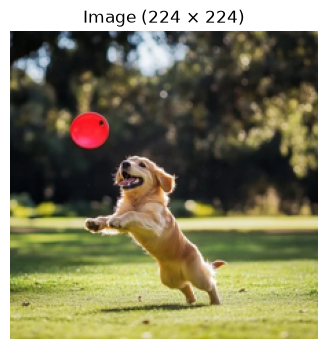

Original size: (512, 512)
Working size:  (224, 224)
As numpy array: (224, 224, 3)  — (H, W, C)


In [2]:
def load_image(path_or_url):
    """Load an image from a local path or a URL, at its original resolution."""
    if path_or_url.startswith('http'):
        response = requests.get(path_or_url)
        return Image.open(BytesIO(response.content)).convert('RGB')
    return Image.open(path_or_url).convert('RGB')

# Load the dog-frisbee image from the slides
img_full = load_image('dog-frisbee.jpeg')   # original resolution (for BLIP)
img = img_full.resize((224, 224))           # 224 x 224 (for patching + DINOv2)

plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.title("Image (224 × 224)")
plt.axis('off')
plt.show()

print(f"Original size: {img_full.size}")
print(f"Working size:  {img.size}")
print(f"As numpy array: {np.array(img).shape}  — (H, W, C)")

---
## Part 1: Patch Embedding from Scratch

The key insight of ViT: **divide the image into fixed-size patches** and treat each patch as a "token."

For a 224×224 image with patch size 16:
- Number of patches per row: 224 ÷ 16 = **14**
- Total patches: 14 × 14 = **196 visual tokens**

### Step 1: Chop the image into patches

In [3]:
def extract_patches(image, patch_size=16):
    """
    Chop an image into non-overlapping patches.
    
    Args:
        image: PIL Image (H x W x 3)
        patch_size: size of each square patch
    
    Returns:
        patches: numpy array of shape (num_patches, patch_size, patch_size, 3)
        grid_size: number of patches per row/column
    """
    img_array = np.array(image)  # (H, W, 3)
    H, W, C = img_array.shape
    grid_size = H // patch_size  # 224 // 16 = 14
    
    patches = []
    for i in range(grid_size):
        for j in range(grid_size):
            patch = img_array[
                i * patch_size : (i + 1) * patch_size,
                j * patch_size : (j + 1) * patch_size,
                :
            ]
            patches.append(patch)
    
    return np.array(patches), grid_size

patches, grid_size = extract_patches(img, patch_size=16)
print(f"Extracted {len(patches)} patches, each of shape {patches[0].shape}")
print(f"Grid: {grid_size} × {grid_size} = {grid_size**2} patches")

Extracted 196 patches, each of shape (16, 16, 3)
Grid: 14 × 14 = 196 patches


### Step 2: Visualize the patches

Let's see what the model sees — the image decomposed into its patch tokens.

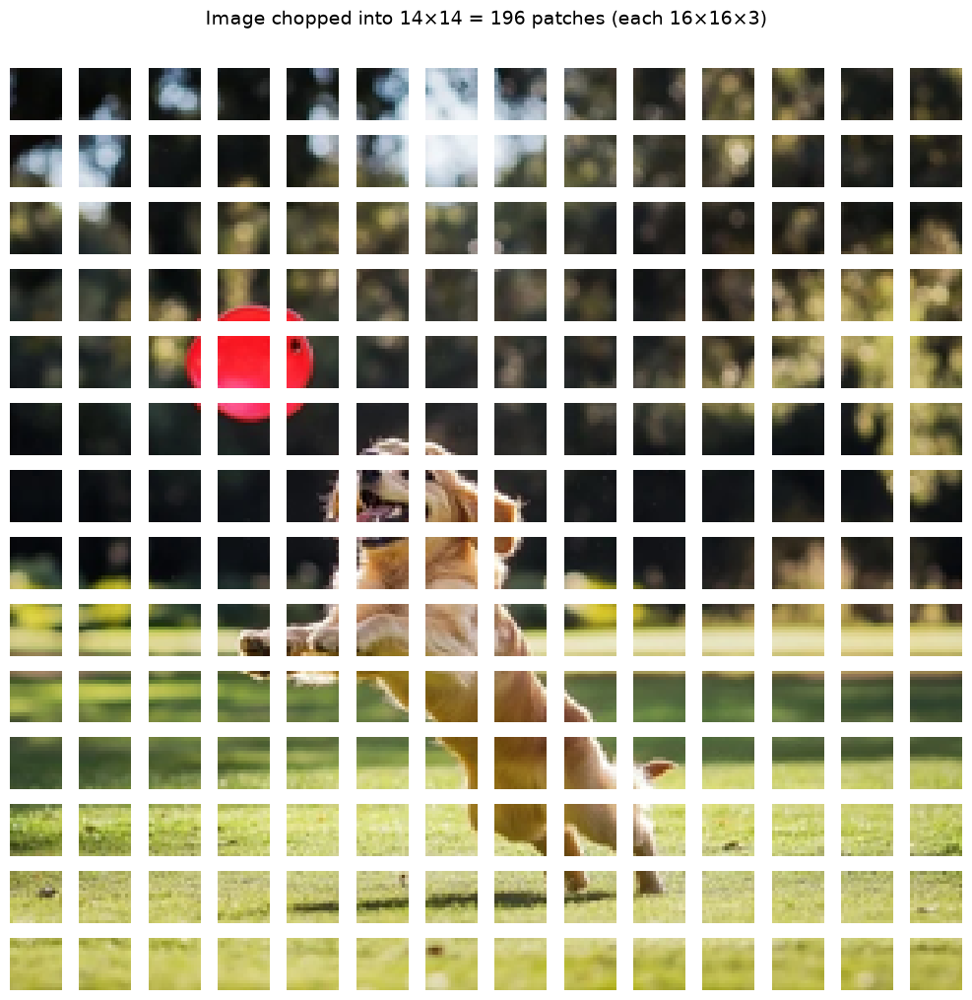

In [4]:
fig, axes = plt.subplots(grid_size, grid_size, figsize=(10, 10))
for i in range(grid_size):
    for j in range(grid_size):
        idx = i * grid_size + j
        axes[i, j].imshow(patches[idx])
        axes[i, j].axis('off')

plt.suptitle(f"Image chopped into {grid_size}×{grid_size} = {grid_size**2} patches (each 16×16×3)", 
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### Step 3: Flatten and project — the patch embedding

Each 16×16×3 patch gets:
1. **Flattened** into a vector of length 16 × 16 × 3 = 768
2. **Linearly projected** to the model dimension *d* (we'll use d=384 to match DINOv2 ViT-S)

$$\mathbf{z}_i = \mathbf{E} \cdot \text{flatten}(\text{patch}_i) + \mathbf{b}$$

This is just `nn.Linear(768, 384)` — nothing exotic!

In [5]:
# Flatten each patch
patches_flat = patches.reshape(len(patches), -1)  # (196, 768)
print(f"Flattened patches shape: {patches_flat.shape}")
print(f"Each patch is now a vector of length {patches_flat.shape[1]}")

# Linear projection (from scratch, using nn.Linear)
d_model = 384  # DINOv2 ViT-S uses d=384
patch_dim = patches_flat.shape[1]  # 768

# This is the patch embedding layer — a single linear projection
patch_embed = nn.Linear(patch_dim, d_model)

# Convert to tensor and project
patches_tensor = torch.tensor(patches_flat, dtype=torch.float32) / 255.0  # normalize to [0,1]
with torch.no_grad():
    patch_embeddings = patch_embed(patches_tensor)  # (196, 384)

print(f"\nPatch embeddings shape: {patch_embeddings.shape}")
print(f"→ 196 tokens, each a {d_model}-dimensional vector")
print(f"\nThis is the SAME shape as a sequence of word embeddings!")
print(f"Compare: the word2vec/RNN assignment used nn.Embedding to map word indices → vectors.")
print(f"Here we use nn.Linear to map pixel patches → vectors.")

Flattened patches shape: (196, 768)
Each patch is now a vector of length 768

Patch embeddings shape: torch.Size([196, 384])
→ 196 tokens, each a 384-dimensional vector

This is the SAME shape as a sequence of word embeddings!
Compare: the word2vec/RNN assignment used nn.Embedding to map word indices → vectors.
Here we use nn.Linear to map pixel patches → vectors.


### Step 4: Visualize the embedding space

Our `nn.Linear` is **untrained** — its weights are random. Does the embedding space mean anything yet?

Surprisingly, partly yes: a random linear projection roughly *preserves distances* between the input vectors (the Johnson–Lindenstrauss lemma). So patches with similar **raw pixels** (e.g., two patches of green grass) will still have similar embeddings.

What a random projection *can't* do is capture **meaning** — a patch of dog fur and a patch of the dog's ear look different in pixels, so they won't be close here. Training is what makes semantically related patches land near each other.

❓ **Predict before running:** Which patches will be most similar to the center patch?

**Prediction.** The center patch falls on the dog's golden fur. I expect other patches with a similar mix of tan and shaded pixels to score highly, even if they are some distance from the center.

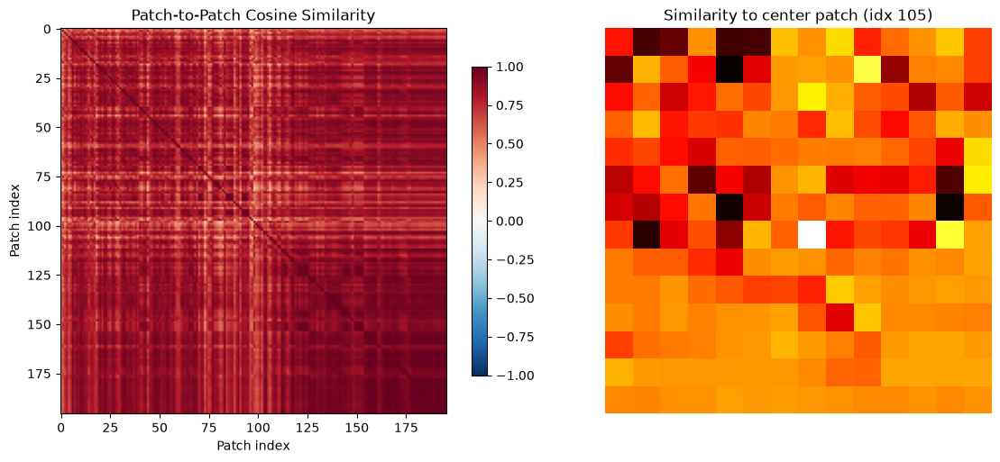

Note: these are RANDOM projections (untrained nn.Linear).
Similarity here reflects raw pixel similarity (color, brightness),
not meaning. A trained ViT learns projections where semantically
similar patches (e.g., both showing fur) map to similar vectors.


In [6]:
# Compute cosine similarity between all patch pairs
norms = patch_embeddings / patch_embeddings.norm(dim=1, keepdim=True)
similarity = (norms @ norms.T).detach().numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Full similarity matrix
im = axes[0].imshow(similarity, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set_title("Patch-to-Patch Cosine Similarity")
axes[0].set_xlabel("Patch index")
axes[0].set_ylabel("Patch index")
plt.colorbar(im, ax=axes[0], shrink=0.8)

# Similarity of one patch to all others, reshaped to the image grid
query_patch = grid_size * (grid_size // 2) + (grid_size // 2)  # center patch
sim_map = similarity[query_patch].reshape(grid_size, grid_size)
axes[1].imshow(sim_map, cmap='hot')
axes[1].set_title(f"Similarity to center patch (idx {query_patch})")
axes[1].axis('off')

plt.tight_layout()
plt.show()

print("Note: these are RANDOM projections (untrained nn.Linear).")
print("Similarity here reflects raw pixel similarity (color, brightness),")
print("not meaning. A trained ViT learns projections where semantically")
print("similar patches (e.g., both showing fur) map to similar vectors.")

**Observation.** Patch 105 matches itself exactly. Other bright squares are scattered through the trees and grass as well as near the dog. The random projection can match the color and brightness pattern in a patch without grouping the whole dog together.

---
## Part 2: Loading a Pretrained Vision Transformer (DINOv2)

Now let's see what a *trained* ViT actually does. We'll use **DINOv2** (Meta AI), a self-supervised ViT that learns strong visual representations without any labels.

**Why DINOv2?**
- Self-supervised → the attention maps are especially clean and interpretable
- It learns to *segment objects* without ever being told what an object is
- Small variant (ViT-S/14) runs fine on CPU

**Why the "registers" version?** Large ViTs develop a few *artifact tokens*: background patches the model repurposes as scratch space for global information. They show up as bright, meaningless spots in attention maps (Darcet et al., 2023, *Vision Transformers Need Registers*). The fix: add a few extra learnable **register tokens** to the sequence, giving the model somewhere else to store that information. We use `dinov2_vits14_reg`, which has 4 registers.

So the token sequence is: **[CLS] + 4 registers + patches**.

In [7]:
# Load DINOv2 ViT-Small, patch size 14, with 4 register tokens
model = torch.hub.load('facebookresearch/dinov2:main', 'dinov2_vits14_reg', trust_repo=True)
model.eval()

num_registers = model.num_register_tokens   # 4
n_skip = 1 + num_registers                  # [CLS] + registers come before the patch tokens

print(f"Model loaded: DINOv2 ViT-S/14 (with registers)")
print(f"Patch size: 14 × 14")
print(f"Embedding dim: {model.embed_dim}")
print(f"Number of heads: {model.blocks[0].attn.num_heads}")
print(f"Number of layers: {len(model.blocks)}")
print(f"Register tokens: {num_registers}")

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Using cache found in C:\Users\admin123/.cache\torch\hub\facebookresearch_dinov2_main
C:\Users\admin123/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
C:\Users\admin123/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
C:\Users\admin123/.cache\torch\hub\facebookresearch_dinov2_main\dinov2\layers\block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Model loaded: DINOv2 ViT-S/14 (with registers)
Patch size: 14 × 14
Embedding dim: 384
Number of heads: 6
Number of layers: 12
Register tokens: 4
Total parameters: 22,058,112


In [8]:
# Preprocessing — same transforms DINOv2 expects
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],   # ImageNet stats
                         std=[0.229, 0.224, 0.225]),
])

# Prepare our image
img_tensor = transform(img).unsqueeze(0)  # (1, 3, 224, 224)
print(f"Input tensor shape: {img_tensor.shape}")

# How many patches for DINOv2 with patch_size=14?
patch_size_dino = 14
num_patches_per_side = 224 // patch_size_dino  # 16
num_patches = num_patches_per_side ** 2        # 256
print(f"Patches: {num_patches_per_side} × {num_patches_per_side} = {num_patches}")
print(f"Plus 1 [CLS] + {num_registers} registers → {num_patches + n_skip} total tokens")

Input tensor shape: torch.Size([1, 3, 224, 224])
Patches: 16 × 16 = 256
Plus 1 [CLS] + 4 registers → 261 total tokens


---
## Part 3: Extracting and Visualizing Attention Weights

We'll run the image through the model and, at the layer we care about, recompute the attention weights ourselves using the same Q, K projections the model uses.

**Remember from Transformers Day 2:**
$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

We want the attention *weights* — the softmax output — not the final values.

In [9]:
def get_attention_maps(model, img_tensor, layer_idx=-1):
    """
    Extract attention weights from one layer of the DINOv2 ViT.

    Returns:
        tensor of shape (num_heads, num_tokens, num_tokens),
        where num_tokens = 1 [CLS] + registers + patches
    """
    n_layers = len(model.blocks)
    target = layer_idx % n_layers   # handles negative indices, e.g. -1 -> 11

    with torch.no_grad():
        # Patch embedding + [CLS] + registers + positional encoding
        x = model.prepare_tokens_with_masks(img_tensor)

        for i, blk in enumerate(model.blocks):
            if i < target:
                x = blk(x)   # run earlier layers normally
                continue

            # At the target layer: recompute Q and K and the attention weights
            B, N, C = x.shape
            attn = blk.attn
            qkv = attn.qkv(blk.norm1(x))                                  # (B, N, 3*C)
            qkv = qkv.reshape(B, N, 3, attn.num_heads, C // attn.num_heads)
            qkv = qkv.permute(2, 0, 3, 1, 4)                              # (3, B, heads, N, d_k)
            q, k = qkv[0], qkv[1]

            # Scaled dot-product attention weights — the formula you implemented!
            weights = (q @ k.transpose(-2, -1)) * attn.scale
            weights = weights.softmax(dim=-1)
            return weights.squeeze(0)   # (heads, N, N) — no need to run later layers

# Extract from the last layer
attn_maps = get_attention_maps(model, img_tensor, layer_idx=-1)
print(f"Attention maps shape: {attn_maps.shape}")
print(f"→ {attn_maps.shape[0]} heads, each with {attn_maps.shape[1]} × {attn_maps.shape[2]} attention matrix")
print(f"  ({attn_maps.shape[1]} = 1 [CLS] + {num_registers} registers + {num_patches} patches)")

Attention maps shape: torch.Size([6, 261, 261])
→ 6 heads, each with 261 × 261 attention matrix
  (261 = 1 [CLS] + 4 registers + 256 patches)


### Visualize [CLS] Attention

The **[CLS] token's attention** tells us which patches the model considers most important for representing the whole image.

We take row 0 (the [CLS] token's query), skip the first `n_skip` columns ([CLS] + registers), keep the attention to each patch, and reshape to the patch grid.

**Prediction before viewing the overlay.** I expect the dog and the red disc to stand out against the trees and grass. I expect the caption word *frisbee* to have its strongest visual evidence on the disc.

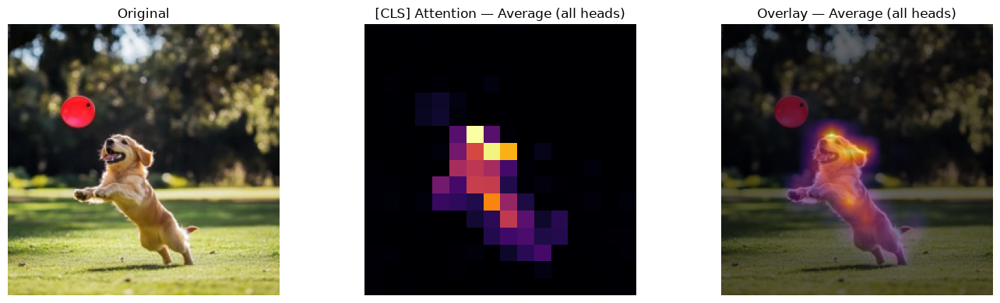

In [10]:
def visualize_cls_attention(img, attn_maps, num_patches_per_side, head_idx=None):
    """
    Overlay [CLS] token attention on the original image.
    
    If head_idx is None, averages across all heads.
    """
    if head_idx is not None:
        # Single head
        cls_attn = attn_maps[head_idx, 0, n_skip:]  # row 0 = [CLS]; skip [CLS] + register columns
        title = f"Head {head_idx}"
    else:
        # Average across heads
        cls_attn = attn_maps[:, 0, n_skip:].mean(dim=0)
        title = "Average (all heads)"
    
    # Reshape to spatial grid
    cls_attn = cls_attn.reshape(num_patches_per_side, num_patches_per_side).detach().numpy()
    
    # Resize attention map to image size for overlay
    attn_resized = np.array(
        Image.fromarray(cls_attn).resize((224, 224), Image.BILINEAR)
    )
    
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    
    axes[0].imshow(img)
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(cls_attn, cmap='inferno')
    axes[1].set_title(f"[CLS] Attention — {title}")
    axes[1].axis('off')
    
    axes[2].imshow(img)
    axes[2].imshow(attn_resized, cmap='inferno', alpha=0.6)
    axes[2].set_title(f"Overlay — {title}")
    axes[2].axis('off')
    
    plt.tight_layout()
    plt.show()

# Average attention across all heads
visualize_cls_attention(img, attn_maps, num_patches_per_side)

**Compare your prediction to the actual result!**

❓ Did the model attend where you expected? Why or why not?

**Observation.** The last-layer average peaks near the dog's forehead and ear and extends down its body. I expected the red disc to stand out too, but it is faint in the average. This map shows how the image-level token pools information. Recognizing a small object for a particular word is a different task.

---
## Part 4: Head Specialization

Remember from Transformers Day 2: Clark et al. (2019) found that BERT's attention heads specialize — some track syntax, others track semantics.

**Do vision attention heads specialize too?** Let's look at each head individually.

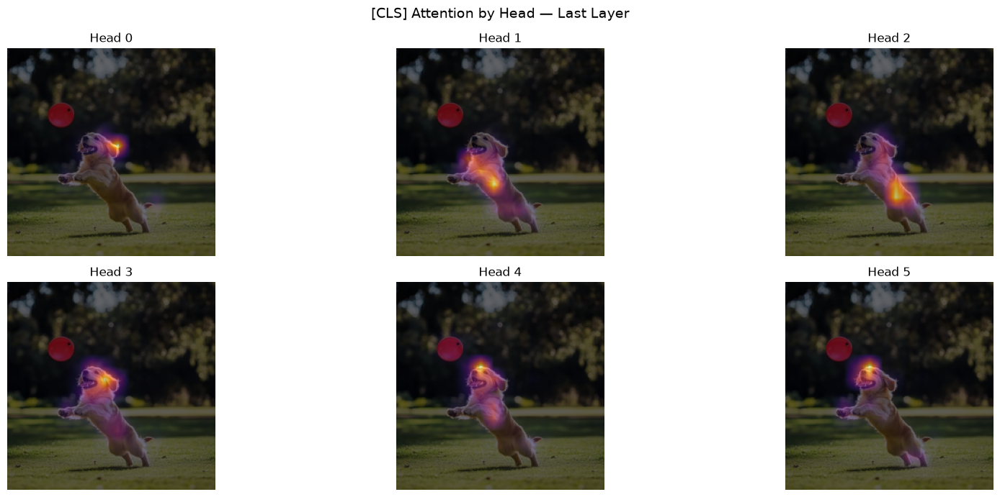

In [11]:
num_heads = attn_maps.shape[0]

fig, axes = plt.subplots(2, num_heads // 2, figsize=(18, 7))
axes = axes.flatten()

for h in range(num_heads):
    cls_attn = attn_maps[h, 0, n_skip:].reshape(num_patches_per_side, num_patches_per_side).detach().numpy()
    
    # Resize for overlay
    attn_resized = np.array(
        Image.fromarray(cls_attn).resize((224, 224), Image.BILINEAR)
    )
    
    axes[h].imshow(img)
    axes[h].imshow(attn_resized, cmap='inferno', alpha=0.6)
    axes[h].set_title(f"Head {h}", fontsize=12)
    axes[h].axis('off')

plt.suptitle("[CLS] Attention by Head — Last Layer", fontsize=14)
plt.tight_layout()
plt.show()

### ❓ Reflection Questions

1. Do different heads attend to different parts of the image? Describe what you see.
2. Can you identify heads that focus on the foreground object vs. the background?
3. How does this compare to CNN filters from Lab 5? (CNN filters detected edges/textures at specific locations; attention heads weigh *relationships* between patches.)

1. Heads 0 and 3 give the dog's ear a bright spot. Head 2 peaks farther down the torso. Heads 4 and 5 put their brightest spots toward the top of the head. Averaging hides the split between the head and the torso.
2. All six heads have their strongest response on the dog. I don't see a head in this layer whose main focus is the trees or grass. Each panel has its own color scale, so I can compare locations more readily than absolute weights.
3. A CNN filter applies the same local kernel at each location. Here the query is the image-level token, and it can assign weight to patches anywhere in the image in one layer. The result depends on the other patches in this photo.

### Try Different Images

Pass a local file path or a URL to the function below. Suggested experiments:
- An image with multiple objects (do heads split between objects?)
- A landscape with no clear subject (where does attention go?)
- A close-up face (which features get attention?)

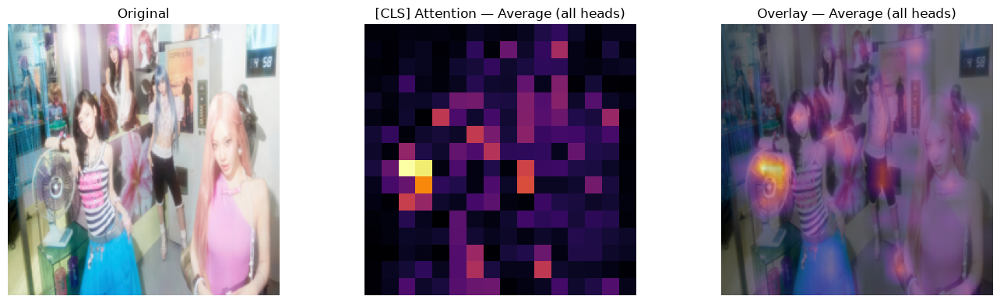

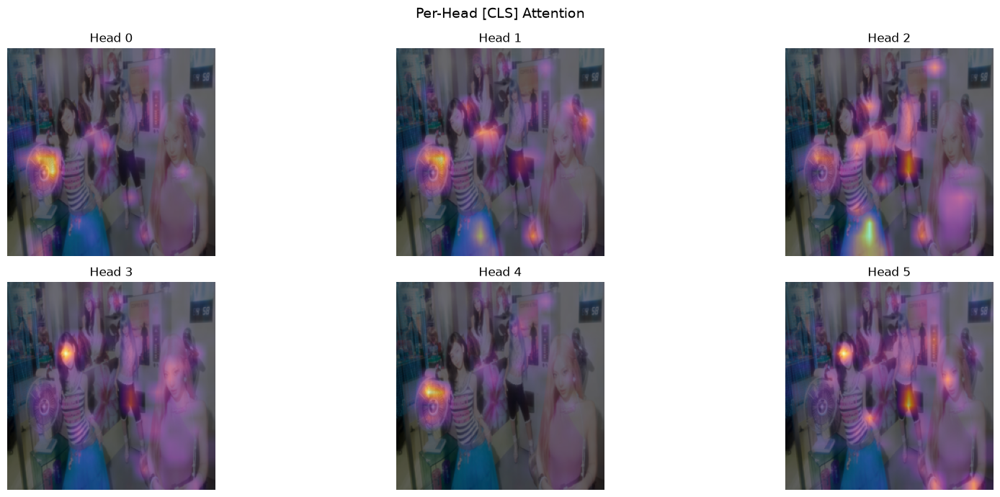

In [12]:
def full_attention_pipeline(path_or_url, model, transform, num_patches_per_side):
    """End-to-end: load image → extract attention → visualize all heads."""
    
    # Load and prepare
    img_new = load_image(path_or_url).resize((224, 224))
    img_tensor_new = transform(img_new).unsqueeze(0)
    
    # Extract attention
    attn_new = get_attention_maps(model, img_tensor_new, layer_idx=-1)
    
    # Visualize average
    visualize_cls_attention(img_new, attn_new, num_patches_per_side)
    
    # Visualize per-head
    num_heads = attn_new.shape[0]
    fig, axes = plt.subplots(2, num_heads // 2, figsize=(18, 7))
    axes = axes.flatten()
    for h in range(num_heads):
        cls_attn = attn_new[h, 0, n_skip:].reshape(num_patches_per_side, num_patches_per_side).detach().numpy()
        attn_resized = np.array(
            Image.fromarray(cls_attn).resize((224, 224), Image.BILINEAR)
        )
        axes[h].imshow(img_new)
        axes[h].imshow(attn_resized, cmap='inferno', alpha=0.6)
        axes[h].set_title(f"Head {h}")
        axes[h].axis('off')
    plt.suptitle("Per-Head [CLS] Attention", fontsize=14)
    plt.tight_layout()
    plt.show()

# My image for both experiments.
own_image_path = "aespa-kiss-n-tell.jpg"
full_attention_pipeline(own_image_path, model, transform, num_patches_per_side)

**My image (aespa).** Heads 0 and 4 both peak on the round fan on the left. Head 3 peaks on the face of the person leaning beside it. Head 5 also picks out that face, with smaller bright spots on other people. The heads split their attention between people and a prop, and several heads share the same target.

---
## Part 5: Comparing Attention Across Layers

Like CNN layers (edges → textures → objects), transformer layers build increasingly abstract representations. Let's compare early vs. late attention.

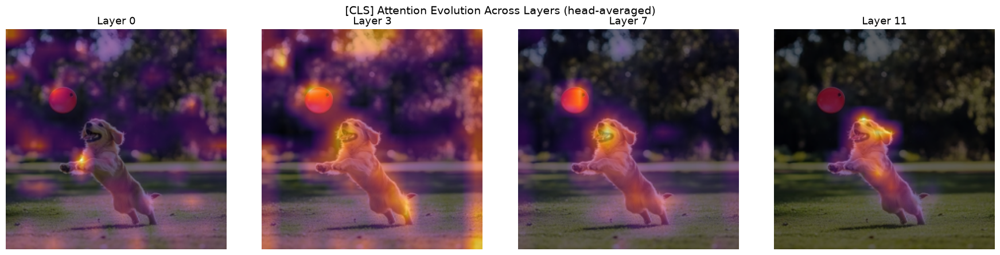

In [13]:
# Extract attention from several layers
layers_to_check = [0, 3, 7, 11]  # early, mid-early, mid-late, last

fig, axes = plt.subplots(1, len(layers_to_check), figsize=(18, 4.5))

for idx, layer in enumerate(layers_to_check):
    attn_layer = get_attention_maps(model, img_tensor, layer_idx=layer)
    # Average across heads, take [CLS] attention
    cls_attn = attn_layer[:, 0, n_skip:].mean(dim=0)
    cls_attn = cls_attn.reshape(num_patches_per_side, num_patches_per_side).detach().numpy()
    attn_resized = np.array(
        Image.fromarray(cls_attn).resize((224, 224), Image.BILINEAR)
    )
    
    axes[idx].imshow(img)
    axes[idx].imshow(attn_resized, cmap='inferno', alpha=0.6)
    axes[idx].set_title(f"Layer {layer}", fontsize=13)
    axes[idx].axis('off')

plt.suptitle("[CLS] Attention Evolution Across Layers (head-averaged)", fontsize=14)
plt.tight_layout()
plt.show()

### ❓ Reflection Questions

1. How does the attention pattern change from early to late layers?
2. Does this remind you of how CNN feature maps evolve? (Lab 5: conv1 detected edges, conv2 detected textures, deeper layers detected parts.)
3. Early ViT layers often show more "diffuse" attention. Why might that be useful?

1. In layer 0, bright spots appear on a front paw and in the trees and grass. Layer 3 still spreads weight across the scene. By layer 7 the disc and the face both stand out. In layer 11 the disc fades and the dog's head and body dominate.
2. This resembles the progression from local details to recognizable parts in the CNN lab. These plots show the destinations of one token's attention. A CNN feature map measures a filter response at each location.
3. Early layers can gather context across the field, trees, and animal before later layers combine those signals. The changing prominence of the disc shows what a last-layer plot alone would miss.

---
## Part 6: Image Captioning — Which Patches Generate Which Words?

So far we've seen **self-attention**: which patches attend to each other.

Now let's answer the opening question: *which parts of the image contribute to each word of a caption?*

We'll use **BLIP** (Bootstrapping Language-Image Pre-training), which has:
- A **ViT image encoder** (ViT-B/16 at 384 × 384 → 24 × 24 = 576 patches)
- A **text decoder** that generates the caption word by word, using **cross-attention** to look at the image patches

In cross-attention, **Q** comes from the caption words and **K, V** come from the image patches. So each word has its own row of attention weights over the patches.

We'll compare two ways of asking "which patches mattered for this word?":
1. **Raw cross-attention weights** — where the word's query looked
2. **Grad-CAM on cross-attention** — the attention weights, scaled by how sensitive the word's prediction is to each one (this is the method the BLIP authors use)

In [14]:
# Install transformers if needed
# !pip install transformers

from transformers import BlipProcessor, BlipForConditionalGeneration

C:\Dev\COMP395\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1111 11:11:03.282000 26492 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [15]:
# Load BLIP
blip_processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base", attn_implementation="eager"
)
blip_model.eval()

print(f"BLIP loaded.")
print(f"Vision encoder: ViT-B/16 — same patch size (16) we used in Part 1, but at 384 × 384")
print(f"Text decoder: {blip_model.config.text_config.num_hidden_layers} layers, "
      f"cross-attention to image patches")


Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 473/473 [00:00<00:00, 44286.58it/s]

BLIP loaded.
Vision encoder: ViT-B/16 — same patch size (16) we used in Part 1, but at 384 × 384
Text decoder: 12 layers, cross-attention to image patches


### Step 1: Generate a caption

Generated caption: 'a dog is playing with a red fr fr fr fr fr fr fr fr fr fr fr fr fr'


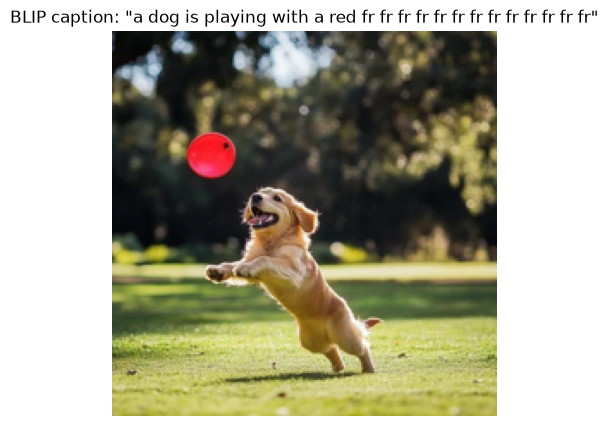

In [16]:
# Generate a caption — use the FULL-RESOLUTION image
# (BLIP resizes to 384 × 384 itself; a 224 thumbnail would lose detail)
blip_inputs = blip_processor(img_full, return_tensors="pt")

with torch.no_grad():
    generated_ids = blip_model.generate(
        **blip_inputs,
        max_new_tokens=20,
        num_beams=5,
        repetition_penalty=1.5,
    )

caption = blip_processor.decode(generated_ids[0], skip_special_tokens=True)
print(f"Generated caption: '{caption}'")

plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.title(f'BLIP caption: "{caption}"', fontsize=12)
plt.axis('off')
plt.show()

### Step 2: Raw attention vs. Grad-CAM for each word

For each word in the caption we compute two heatmaps over the image patches:

**Raw cross-attention** $A_w$: the softmax attention weights from that word's query to every patch (averaged over heads).

**Grad-CAM on cross-attention**:
$$\text{GradCAM}_w = \text{mean}_{\text{heads}}\Big(A_w \odot \text{ReLU}\big(\tfrac{\partial\, \text{logit}_w}{\partial A_w}\big)\Big)$$

In words: keep an attention weight only to the extent that *increasing* it would *increase* the score of the word the model actually produced. This is the chain rule again — we backpropagate from one word's logit to the attention weights.

**Important caveat:** gradients measure *local sensitivity* ("if this weight nudged up a little, how would the score change?"), not true causation. Grad-CAM is a better-informed heatmap than raw attention, but it is still an approximation of what the model "used".

**One detail:** BLIP's decoder starts every caption with a special `[DEC]` token, not `[CLS]`. When we feed the caption back in, we must use the same start token the model used during generation — otherwise we'd be scoring a different sequence than the one it produced.

In [17]:
def caption_heatmaps(blip_model, blip_processor, pil_img, caption, layer=8):
    """
    For each word in the caption, compute:
      - raw cross-attention over image patches
      - Grad-CAM on cross-attention (attention * ReLU(gradient))

    Args:
        layer: which text-decoder layer's cross-attention to use (0-11).
               Middle-to-late layers usually give the most localized maps.

    Returns:
        word_labels, raw_maps, gradcam_maps, patches_per_side
    """
    inputs = blip_processor(pil_img, text=caption, return_tensors='pt')
    input_ids = inputs['input_ids'].clone()
    attention_mask = inputs['attention_mask']

    # BLIP's decoder uses [DEC] as its start token during generation — match it
    input_ids[:, 0] = blip_model.config.text_config.bos_token_id
    raw_tokens = blip_processor.tokenizer.convert_ids_to_tokens(input_ids[0])
    raw_tokens[0] = '[DEC]'  # The checkpoint specifies this ID outside the base tokenizer vocabulary.
    print(f"Tokens: {raw_tokens}")

    # Image features (no gradient needed through the vision encoder)
    with torch.no_grad():
        image_embeds = blip_model.vision_model(
            pixel_values=inputs['pixel_values']).last_hidden_state   # (1, 1 + P, 768)

    # One forward pass through the decoder, keeping the cross-attention weights
    out = blip_model.text_decoder(
        input_ids=input_ids,
        attention_mask=attention_mask,
        encoder_hidden_states=image_embeds,
        output_attentions=True,
        return_dict=True,
    )
    attn = out.cross_attentions[layer]   # (1, heads, seq_len, 1 + P)

    num_patches = attn.shape[-1] - 1     # minus the image [CLS] token
    ps = int(num_patches ** 0.5)         # 24 for BLIP at 384 x 384

    token_raw, token_cam = [], []
    for t in range(1, input_ids.shape[1]):          # each token after the start token
        # logits at position t-1 predict the token at position t
        logit = out.logits[0, t - 1, input_ids[0, t]]
        gradient, = torch.autograd.grad(logit, attn, retain_graph=t < input_ids.shape[1] - 1)

        A = attn[0, :, t - 1, 1:].detach()          # (heads, P) — skip image [CLS]
        G = gradient[0, :, t - 1, 1:]              # (heads, P)

        raw = A.mean(dim=0)
        cam = (A * G.clamp(min=0)).mean(dim=0)
        token_raw.append((raw / raw.max()).reshape(ps, ps).numpy())
        token_cam.append((cam / cam.max() if cam.max() > 0 else cam).reshape(ps, ps).numpy())

    # Merge WordPiece subwords ("fr", "##is", "##bee") into whole words
    word_labels, raw_maps, cam_maps = [], [], []
    cur_word, cur_raw, cur_cam = '', [], []
    for t in range(1, len(raw_tokens)):
        tok = raw_tokens[t]
        if tok in ('[SEP]', '[PAD]'):
            continue
        if tok.startswith('##'):
            cur_word += tok[2:]
            cur_raw.append(token_raw[t - 1]); cur_cam.append(token_cam[t - 1])
        else:
            if cur_word:
                word_labels.append(cur_word)
                raw_maps.append(np.mean(cur_raw, axis=0)); cam_maps.append(np.mean(cur_cam, axis=0))
            cur_word, cur_raw, cur_cam = tok, [token_raw[t - 1]], [token_cam[t - 1]]
    if cur_word:
        word_labels.append(cur_word)
        raw_maps.append(np.mean(cur_raw, axis=0)); cam_maps.append(np.mean(cur_cam, axis=0))

    return word_labels, raw_maps, cam_maps, ps

word_labels, raw_maps, gradcam_maps, blip_patches_per_side = caption_heatmaps(
    blip_model, blip_processor, img_full, caption)

print(f"\nWords: {word_labels}")
print(f"Patch grid: {blip_patches_per_side} × {blip_patches_per_side}")

Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', '[SEP]']



Words: ['a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr']
Patch grid: 24 × 24


### Step 3: Visualize — raw attention vs. Grad-CAM

Top row of each pair: raw cross-attention. Bottom row: Grad-CAM. Look for whether each method gives *different* maps for different words.

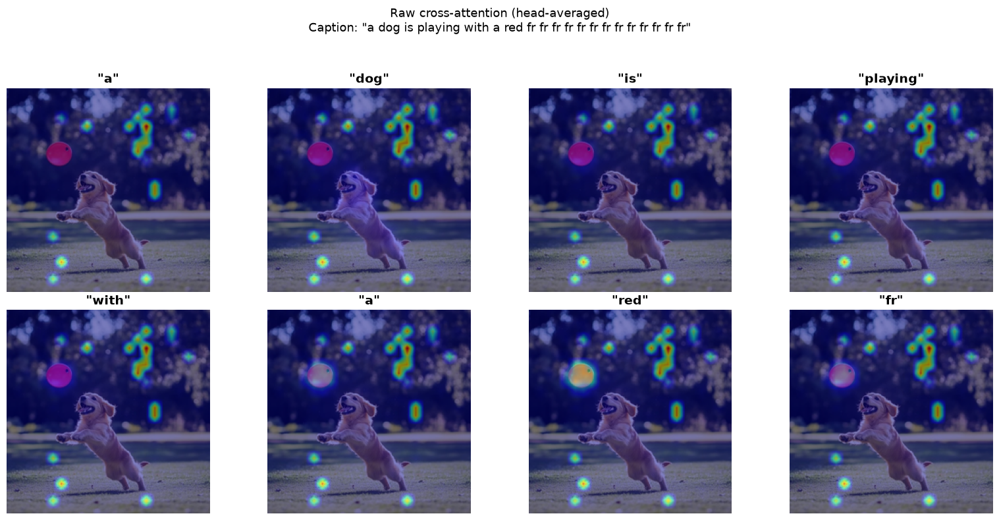

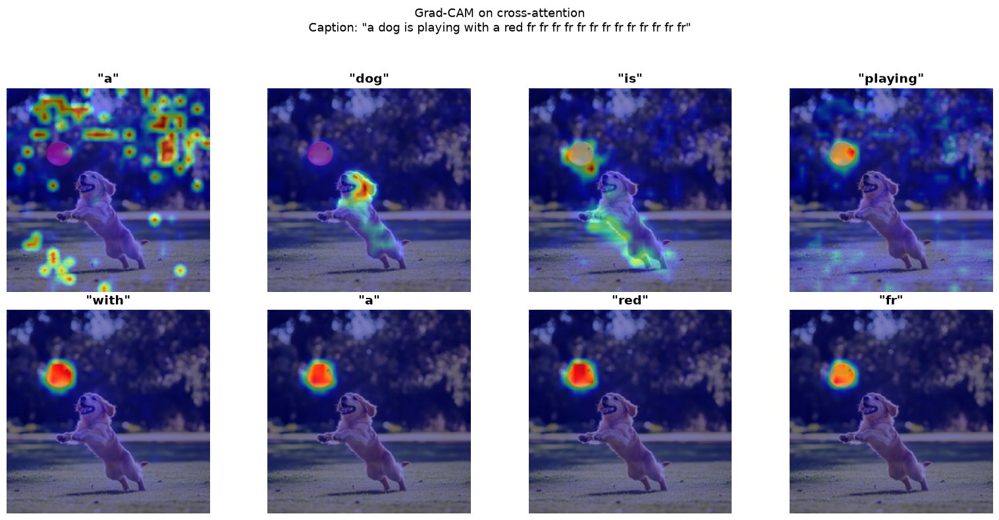

In [18]:
def visualize_word_maps(img, word_labels, maps, title, max_words=None):
    """Overlay one heatmap per caption word on the image."""
    n = len(word_labels) if max_words is None else min(len(word_labels), max_words)
    cols = min(n, 4)
    rows = (n + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 4 * rows))
    axes = np.array(axes).flatten()

    for idx in range(n):
        cam_resized = np.array(
            Image.fromarray(maps[idx].astype(np.float32)).resize(img.size, Image.BILINEAR)
        )
        axes[idx].imshow(img)
        axes[idx].imshow(cam_resized, cmap='jet', alpha=0.5, vmin=0, vmax=1)
        axes[idx].set_title(f'"{word_labels[idx]}"', fontsize=14, fontweight='bold')
        axes[idx].axis('off')

    for j in range(n, len(axes)):
        axes[j].axis('off')

    plt.suptitle(f'{title}\nCaption: "{" ".join(word_labels)}"', fontsize=13)
    plt.tight_layout(rect=(0, 0, 1, 0.94))
    plt.show()

# After the first eight positions, the baseline caption only repeats "fr".
visualize_word_maps(img, word_labels, raw_maps, "Raw cross-attention (head-averaged)", max_words=8)
visualize_word_maps(img, word_labels, gradcam_maps, "Grad-CAM on cross-attention", max_words=8)

Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', '[SEP]']


Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', '##is', '##bee', '[SEP]']


Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', '##is', '##bee', '[SEP]']


Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', 'fr', '[SEP]']


Tokens: ['[DEC]', 'a', 'dog', 'is', 'playing', 'with', 'a', 'red', 'fr', '##is', '##bee', '[SEP]']


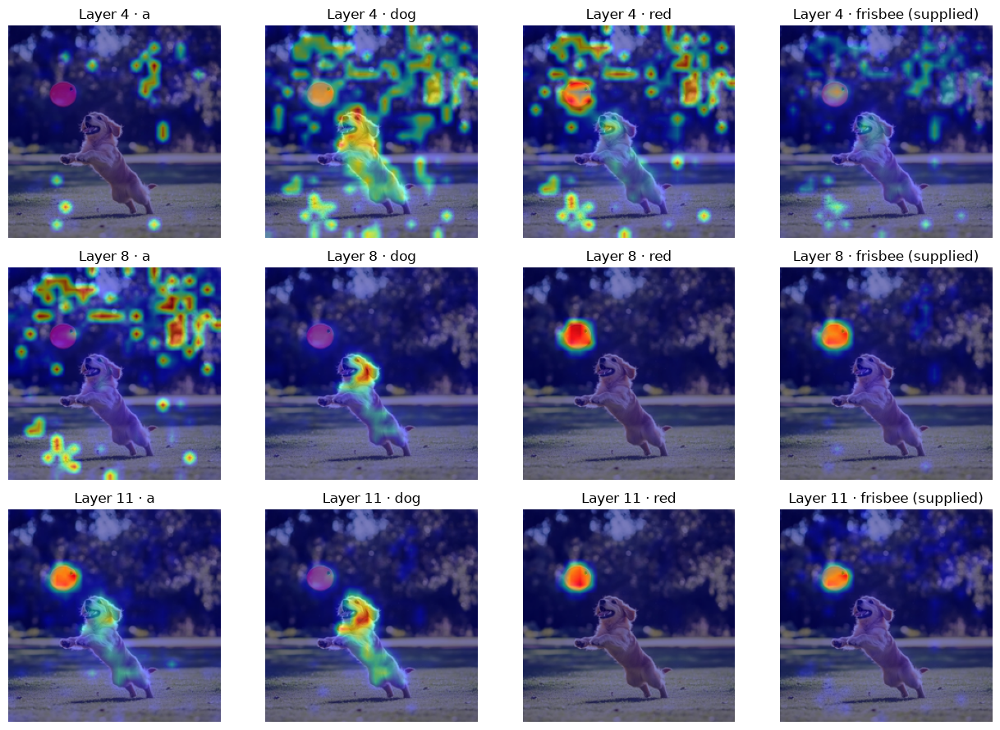

In [19]:
# Compare generated words with a separate teacher-forced probe for the missing noun.
# The probe uses the same beginning as the generated caption.
probe_caption = "a dog is playing with a red frisbee"
layers = (4, 8, 11)
selected = [word_labels.index(word) for word in ("a", "dog", "red") if word in word_labels]
fig, axes = plt.subplots(len(layers), len(selected) + 1,
                         figsize=(3.2 * (len(selected) + 1), 9), squeeze=False)
for row, layer in enumerate(layers):
    if layer == 8:
        cams = gradcam_maps
    else:
        labels, _, cams, _ = caption_heatmaps(blip_model, blip_processor, img_full, caption, layer)
        assert labels == word_labels
    probe_words, _, probe_cams, _ = caption_heatmaps(
        blip_model, blip_processor, img_full, probe_caption, layer)
    panels = [(word_labels[i], cams[i]) for i in selected]
    panels.append(("frisbee (supplied)", probe_cams[probe_words.index("frisbee")]))
    for ax, (word, cam) in zip(axes[row], panels):
        heat = Image.fromarray(cam).resize(img.size, Image.Resampling.BILINEAR)
        ax.imshow(img)
        ax.imshow(np.asarray(heat), cmap='jet', vmin=0, vmax=1, alpha=0.5)
        ax.set_title(f'Layer {layer} · {word}')
        ax.axis('off')
plt.tight_layout()
plt.show()

### ❓ Compare to Your Opening Prediction

Pull out the sketch you made at the start of class.

1. **Did the model focus where you predicted?** Which words surprised you?
2. **Look at the word for the frisbee.** It covers only about 1–2% of the image, but it's critical to the caption. Does Grad-CAM highlight it?
3. **Compare content words vs. function words.** Do nouns ("dog", "frisbee") produce sharper, more localized heatmaps than articles ("a", "the")?
4. **Raw attention vs. Grad-CAM:** Do the raw attention maps differ much from word to word? Do the Grad-CAM maps? What does this tell you about reading attention weights as explanations?
5. **Change the layer:** re-run `caption_heatmaps(..., layer=4)` and `layer=11`. How do the maps change?
6. **How does this compare to DINOv2's self-attention** from Part 3? DINOv2 had no text — it was purely visual. These maps are *guided by language*.

1. The layer-8 map for *dog* peaks on the head. The map for *red* isolates the disc, as predicted for the object. The second *a* surprised me because its map also peaks on the disc, while the opening *a* lights up scattered background patches.
2. BLIP generated *fr* repeatedly after *red* until it reached the 20-token limit. There is no generated whole word *frisbee* to score. In the separate probe, I supplied “a dog is playing with a red frisbee” and combined the maps for `fr`, `##is`, and `##bee`. At layer 8 the combined Grad-CAM peak lands on the red disc.
3. The generated noun *dog* is more localized than the first *a*. The second *a* is also sharply localized, so part of speech alone doesn't explain how narrow the map is. The preceding words differ at the two article positions.
4. Raw cross-attention repeats several bright spots in the upper-right foliage and on the ground across words. Grad-CAM shifts from the dog's face for *dog* to the disc for *red*. The color scales are relative to each map's own peak, so brightness cannot establish which word was more sensitive overall.
5. Layer 4 includes the objects along with many bright background patches. Layer 8 isolates the dog and the disc more cleanly. At layer 11, *red* and the supplied *frisbee* still peak on the disc, while the first *a* has shifted toward the disc and dog.
6. DINOv2's last-layer image summary emphasizes the dog and gives little weight to the disc. BLIP can shift between both objects in the same layer because each decoder position has a different query determined by the preceding words.

### Step 4: Try your own images

Caption: 'a group of girls standing in a room'


Tokens: ['[DEC]', 'a', 'group', 'of', 'girls', 'standing', 'in', 'a', 'room', '[SEP]']


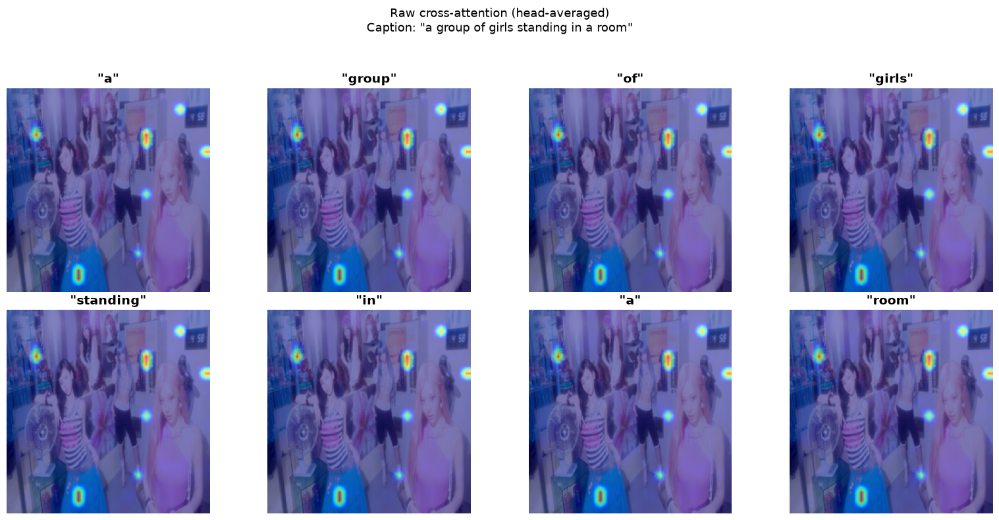

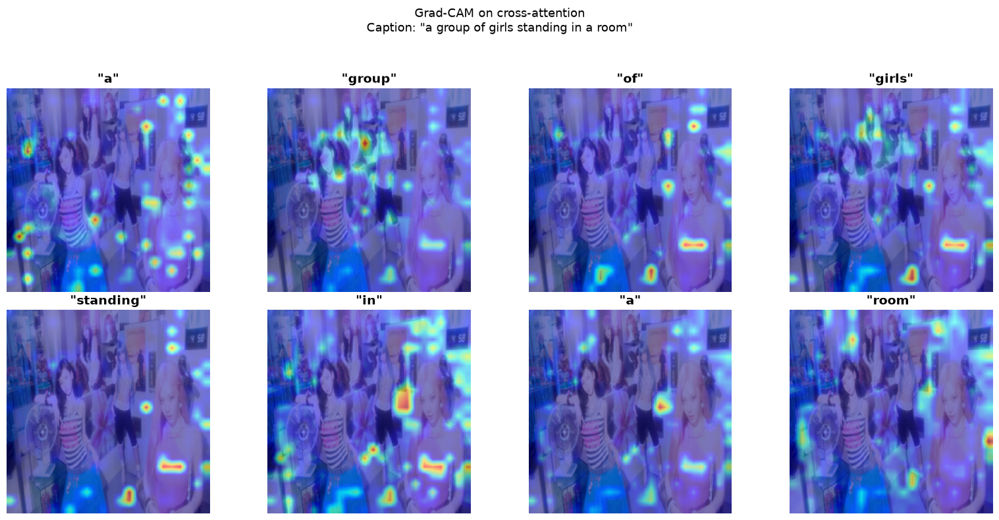

In [20]:
def caption_and_visualize(path_or_url, blip_model, blip_processor, layer=8):
    """Full pipeline: load image -> caption -> heatmaps -> visualize."""
    new_full = load_image(path_or_url)           # full resolution for BLIP
    new_small = new_full.resize((224, 224))      # for display

    inputs = blip_processor(new_full, return_tensors='pt')
    with torch.no_grad():
        gen_ids = blip_model.generate(
            **inputs, max_new_tokens=20,
            num_beams=5, repetition_penalty=1.5
        )
    new_caption = blip_processor.decode(gen_ids[0], skip_special_tokens=True)
    print(f"Caption: '{new_caption}'")

    words, raws, cams, _ = caption_heatmaps(blip_model, blip_processor, new_full, new_caption, layer)
    visualize_word_maps(new_small, words, raws, "Raw cross-attention (head-averaged)")
    visualize_word_maps(new_small, words, cams, "Grad-CAM on cross-attention")

caption_and_visualize(own_image_path, blip_model, blip_processor)

**My image (aespa).** BLIP generated “a group of girls standing in a room.” It captures the indoor group scene and leaves out the fan that stood out in DINOv2. The raw maps show nearly the same bright spots for every word. In the layer-8 Grad-CAM maps, *group* highlights several people across the center, while *room* also highlights parts of the upper background and the edges of the scene.

### ❓ Reflection

1. **Connection to the word2vec/RNN assignment:** The old approach to image captioning used a CNN to encode the image into a single fixed vector, then an RNN decoded the caption. That single vector had to capture *everything*. Cross-attention lets the decoder look back at specific patches for each word. Why is that better?
2. **Attention ≠ Explanation?** Attention weights show where a query *looked*; that's not necessarily what *mattered* for the output. Jain & Wallace (2019, "Attention is not Explanation") found attention weights often don't line up with other measures of feature importance; Wiegreffe & Pinter (2019, "Attention is not not Explanation") argued the picture is more nuanced. Based on what you saw, which side do you find more convincing for this model?
3. **Connection to backpropagation:** Grad-CAM is the chain rule again. We backpropagate from one word's logit to the attention weights. You've been doing this since Assignment 1. But remember: a gradient describes *local sensitivity*, not causation.

1. With one fixed image vector, the same compressed summary has to carry the dog's pose, the disc's color, and the background through every decoding step. Cross-attention gives the decoder direct access to the grid of patch features each time it predicts a token. In my group photo, the Grad-CAM map for *group* highlights several people together, while the one for *room* also picks up patches near the edges of the scene.
2. For this model, I find the skeptical interpretation more convincing for raw attention alone. Several raw maps share bright background spots even though *dog* and *red* have different visual referents. The gradients help distinguish those words, but a bright disc in a heatmap didn't guarantee the decoder would finish spelling *frisbee*.
3. For a target token at position $t$, the score comes from the logits at $t-1$. Backpropagation gives the derivative of that score with respect to each cross-attention weight. Weighting attention by its positive gradient picks out patches where a small increase in weight would locally raise the score. Removing the disc and regenerating the caption would test a different question about changing the input.

---
## Summary

| Concept | Connection |
|---------|------------|
| Patch embedding | Like `nn.Embedding` but with a linear projection instead of a lookup table |
| [CLS] token | Same role as BERT's [CLS] — aggregate the full input |
| Positional encoding | Required because attention is permutation equivariant (Transformers Day 2) |
| Attention heads specialize | Same as Clark et al. finding for BERT; also like CNN filters detecting different patterns (Lab 5) |
| Layer depth | Like CNN depth: early = local features, late = global semantics |
| Self-attention (DINOv2) | Image patches attend to each other — discovers objects without labels; register tokens remove artifact spots |
| Grad-CAM (BLIP) | Attention weights scaled by their gradients show which patches each caption word is sensitive to — backprop from Assignment 1! |
| Attention ≠ Explanation? | Raw attention shows where a query looked, not necessarily what mattered; gradients add sensitivity information but are not causal |
| Patch sequence (196 tokens) | Much longer than typical text sequences — computational cost matters |